# Quantifying Attributions for Arousal Prediction
In this notebook, we:
- Load attribution results of the configurations `frozen_arousal`, `from_scratch_arousal` and `finetuned_arousal`,
  **15 independent runs** in total (5 per configuration), using `ExperimentResults` and `AttributionAnalyzer`
  (the same three configurations and run count as the PhysioMI analysis)
- Compute per-run spatial aggregate relevance vectors $M^{(r)} \in \mathbb{R}^{60}$
- Test for each electrode whether its relevance is higher than the background with a one-sided **Mann–Whitney U test**,
  **Benjamini–Hochberg FDR-corrected**, reported in APA style (section 2)
- Compute the **Spearman rank correlation** ($\rho$) between each electrode's relative relevance and the test set
  **balanced accuracy** across runs (section 3)
- Visualize the aggregate relevance and the correlations as topomaps (section 4)
- Write booktabs tables and a statistics cache to `results/apa_mwu/` (section 5)

This notebook is the only implementation of this analysis: `script/quantify_attr_arousal.py` just executes it
(`python script/quantify_attr_arousal.py`), and all outputs the script used to write (per-electrode test and
Spearman CSVs, topomap figure) are written by this notebook to `results/apa_mwu/`.

**Data.** The run folders are read from `out/frozen_arousal`, `out/from_scratch_arousal` and `out/finetuned_arousal`;
the channel order from
`out/channels_ordered_brain_heart_emotion.pkl`. See section 1 for where they come from.

In [1]:
%load_ext autoreload
%autoreload 2
import sys, os, pickle
sys.path.append(os.path.abspath(os.path.join('..', '..', 'src')))

import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ranksums, spearmanr, false_discovery_control

from evaluate.analysis_utils import ExperimentResults, AttributionAnalyzer
from visualization.eeg_attribution import attribution_topomap

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

## Statistical test and reporting helpers

All group comparisons in this notebook use the **Mann–Whitney U test** (`scipy.stats.mannwhitneyu`) with
**normal approximation, tie correction and no continuity correction**.
Without ties this yields exactly the z and p of `scipy.stats.ranksums`, which earlier versions of the analysis used.

Every test reports, in APA style:
* each group characterized by *n*, median (Mdn) and interquartile range (IQR = Q1–Q3),
* *U* (statistic of the first-named group: number of pairs in which its value is larger, ties counting ½),
* *z* (tie-corrected; *z* > 0 means the first-named group tends to be larger),
* *p* (and the FDR-adjusted *p* where several tests are run),
* the effect size *r* = *z* / √*N*, and *A* = *U* / (*n*₁*n*₂), the probability that a random value of the first group exceeds one of the second.

The cell also defines the booktabs (LaTeX) table builder and `write_output`, which saves the `.tex` tables and a
`.json` statistics cache (inputs, results, code and library versions, data locations) to `results/apa_mwu/`.
This cell is identical in the four notebooks that report these statistics (listed at the top of the cell).

In [2]:
# ---- Mann–Whitney U test with APA reporting, booktabs tables and a statistics cache ----
# This cell is identical in quantifying_attr_on_arousal.ipynb, quantifying_attr_on_physiomi.ipynb,
# clever_hans_lateral_holdout_mwu.ipynb and electrode_statistics_summary.ipynb.
import datetime
import json
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import mannwhitneyu, norm

# Repository root (folder holding pyproject.toml), independent of where the kernel was started.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
STATS_DIR = PROJECT_ROOT / "results" / "apa_mwu"  # .tex tables and .json statistics caches are written here

# Normal approximation with tie correction, without continuity correction.
# Without ties this gives exactly the z and p of scipy.stats.ranksums (checked below where ranksums was used before).
MWU_SETTINGS = {"method": "asymptotic", "use_continuity": False}
MWU_SETTINGS_TEXT = "normal approximation with tie correction, no continuity correction"


def mwu_apa(x, y, alternative, label_x, label_y):
    """Mann–Whitney U test of x vs. y, returning every quantity needed for APA reporting.

    U    statistic of x: number of pairs (x_i, y_j) with x_i > y_j, ties counting 1/2 (scipy's convention).
    z    (U - n_x n_y / 2) / sigma_U with the tie-corrected sigma_U; z > 0 means x tends to be larger than y.
    p    from z under the given alternative ("greater": x tends to be larger than y).
    r    effect size z / sqrt(n_x + n_y).
    A    U / (n_x n_y), the probability that a random x exceeds a random y (common-language effect size).
    Mdn, Q1, Q3 describe each group (IQR = Q1–Q3, linear interpolation).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n_x, n_y = len(x), len(y)
    n = n_x + n_y
    res = mannwhitneyu(x, y, alternative=alternative, **MWU_SETTINGS)
    u = float(res.statistic)
    _, tie_sizes = np.unique(np.concatenate([x, y]), return_counts=True)
    sigma_u = np.sqrt(n_x * n_y / 12 * ((n + 1) - np.sum(tie_sizes**3 - tie_sizes) / (n * (n - 1))))
    z = (u - n_x * n_y / 2) / sigma_u
    # scipy does not return z; the p-value recomputed from our z must equal scipy's p-value
    p_from_z = {"greater": norm.sf(z), "less": norm.cdf(z), "two-sided": 2 * norm.sf(abs(z))}[alternative]
    assert np.isclose(p_from_z, res.pvalue, rtol=1e-9, atol=0), (p_from_z, res.pvalue)
    (q1_x, mdn_x, q3_x), (q1_y, mdn_y, q3_y) = np.percentile(x, [25, 50, 75]), np.percentile(y, [25, 50, 75])
    return {
        "label_x": label_x, "label_y": label_y, "alternative": alternative,
        "n_x": n_x, "mdn_x": mdn_x, "q1_x": q1_x, "q3_x": q3_x,
        "n_y": n_y, "mdn_y": mdn_y, "q1_y": q1_y, "q3_y": q3_y,
        "U": u, "z": z, "p": float(res.pvalue), "r": z / np.sqrt(n), "A": u / (n_x * n_y),
        "n_tied_values": int(np.sum(tie_sizes[tie_sizes > 1])),  # observations sharing their value with another one
    }


# ---- APA number formatting ----
def fmt_bounded(v, digits=2):
    """Quantities that cannot exceed 1 in absolute value (p, r, rho): no leading zero."""
    return f"{v:.{digits}f}".replace("0.", ".", 1)


def fmt_p(p):
    """'< .001', '> .999' or '= .023'."""
    if p < 0.001:
        return "< .001"
    if p > 0.999:
        return "> .999"
    return "= " + fmt_bounded(p, 3)


def fmt_u(u):
    return f"{u:.1f}".removesuffix(".0")  # U is an integer or ends in .5 (ties)


def describe_group(s, which, digits=3):
    """Characterization of one group, e.g. 'relevance at AF7 (n = 15, Mdn = .041, IQR = .027–.052)'.

    All compared quantities here (relative relevance, balanced accuracy) cannot exceed 1: no leading zero (APA).
    """
    f = lambda v: fmt_bounded(v, digits)
    return (f"{s['label_' + which]} (n = {s['n_' + which]}, Mdn = {f(s['mdn_' + which])}, "
            f"IQR = {f(s['q1_' + which])}–{f(s['q3_' + which])})")


def apa_mwu_text(s, p_adj=None):
    """'U = 11204, z = 4.12, p < .001, r = .14' (with 'p_FDR ...' if an adjusted p-value is given)."""
    text = f"U = {fmt_u(s['U'])}, z = {s['z']:.2f}, p {fmt_p(s['p'])}"
    if p_adj is not None:
        text += f", p_FDR {fmt_p(p_adj)}"
    return text + f", r = {fmt_bounded(s['r'])}"


def apa_mwu_sentence(s, alpha=0.05, p_adj=None, digits=3, describe_y=True):
    """Full sentence: both groups characterized, the direction, and the test statistics.

    Significance is decided on p_adj if given, otherwise on p.
    describe_y=False names the second group without n, Mdn and IQR, for a group that is characterized once
    for many tests (see describe_background).
    """
    significant = (p_adj if p_adj is not None else s["p"]) < alpha
    if s["alternative"] == "greater":
        verdict = "was significantly higher than" if significant else "was not significantly higher than"
    elif s["alternative"] == "less":
        verdict = "was significantly lower than" if significant else "was not significantly lower than"
    elif significant:
        verdict = "was significantly higher than" if s["z"] > 0 else "was significantly lower than"
    else:
        verdict = "did not differ significantly from"
    first = describe_group(s, "x", digits)
    second = describe_group(s, "y", digits) if describe_y else s["label_y"]
    return f"{first[0].upper()}{first[1:]} {verdict} {second}, {apa_mwu_text(s, p_adj)}."


def fmt_range(values, digits=3, dash="–"):
    """'.014' if all values round to the same number, else 'min–max', e.g. '.024–.025'."""
    lo, hi = fmt_bounded(min(values), digits), fmt_bounded(max(values), digits)
    return lo if lo == hi else f"{lo}{dash}{hi}"


def describe_background(results, digits=3, tex=False):
    """One phrase characterizing the background group of all electrode-vs-background tests at once.

    The background of electrode c is all other electrodes, so it hardly changes from test to test. Its n, Mdn, Q1 and
    Q3 are given as ranges over the tests (one value where all tests round to the same number); "virtually identical"
    is only stated if every range spans at most one unit of the last digit shown. The per-test values stay in the
    results (n_y, mdn_y, q1_y, q3_y).
    """
    dash = "--" if tex else "–"
    stats = ", ".join(f"{name} = {fmt_range(results[col], digits, dash)}" for name, col in [("Mdn", "mdn_y"), ("Q1", "q1_y"), ("Q3", "q3_y")])
    n_y = sorted(set(results["n_y"]))
    n_text = str(n_y[0]) if len(n_y) == 1 else f"{n_y[0]}{dash}{n_y[-1]}"
    n_text = f"$n = {n_text}$" if tex else f"n = {n_text}"
    identical = all(results[col].max() - results[col].min() <= 10 ** -digits for col in ["mdn_y", "q1_y", "q3_y"])
    verdict = "was virtually identical in all" if identical else "varied across the"
    return (f"The background group, the relative relevance of all other electrodes in all runs ({n_text} per test), "
            f"{verdict} {len(results)} tests ({stats} across tests).")


# ---- LaTeX (booktabs) output; needs \usepackage{booktabs} (and \usepackage{longtable} for long=True) ----
def tex_p(p):
    return "$< .001$" if p < 0.001 else ("$> .999$" if p > 0.999 else f"${fmt_bounded(p, 3)}$")


def tex_num(v, digits=2, bounded=False):
    return f"${fmt_bounded(v, digits) if bounded else f'{v:.{digits}f}'}$"  # math mode gives a proper minus sign


def booktabs(header, rows, colspec, caption, label, long=False):
    """booktabs table in \\small with narrower column spacing.

    header: list of cells (one header row), or list of rows, where a row is a list of cells or a raw line (e.g. a \\cmidrule).
    long=False: floating table. long=True: longtable that breaks across pages (header repeated), for full electrode lists.
    An empty table gets one row saying so.
    """
    n_cols = sum(ch in "lcr" for ch in colspec)
    rows_of_header = header if isinstance(header[0], list) else [header]
    head = "\n".join(r if isinstance(r, str) else " & ".join(r) + r" \\" for r in rows_of_header)
    body = [" & ".join(row) + r" \\" for row in rows] or [rf"\multicolumn{{{n_cols}}}{{l}}{{No electrode with $p_{{\mathrm{{FDR}}}} < .05$}} \\"]
    if long:
        return "\n".join([
            r"{\small\setlength{\tabcolsep}{4pt}",
            rf"\begin{{longtable}}{{{colspec}}}",
            rf"\caption{{{caption}}}\label{{{label}}} \\",
            r"\toprule", head, r"\midrule", r"\endfirsthead",
            rf"\multicolumn{{{n_cols}}}{{l}}{{\emph{{(continued)}}}} \\",
            r"\toprule", head, r"\midrule", r"\endhead",
            r"\bottomrule", r"\endfoot",
            *body,
            r"\end{longtable}",
            r"}",
        ])
    return "\n".join([
        r"\begin{table}[ht]",
        r"\centering",
        r"\small",
        r"\setlength{\tabcolsep}{4pt}",
        rf"\caption{{{caption}}}",
        rf"\label{{{label}}}",
        rf"\begin{{tabular}}{{{colspec}}}",
        r"\toprule",
        head,
        r"\midrule",
        *body,
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}",
    ])


# ---- Output files ----
def _git(*args):
    return subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, text=True).stdout.strip()


def provenance(data_sources):
    """Everything needed to trace the numbers back: code version, library versions, data locations, test settings."""
    return {
        "created": datetime.datetime.now().isoformat(timespec="seconds"),
        "git_commit": _git("rev-parse", "HEAD"),
        "git_branch": _git("rev-parse", "--abbrev-ref", "HEAD"),
        "git_uncommitted_changes": bool(_git("status", "--porcelain")),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "pandas": pd.__version__,
        "mwu_settings": {**MWU_SETTINGS, "tie_correction": True, "description": MWU_SETTINGS_TEXT},
        "data_sources": data_sources,
    }


def _jsonable(o):
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (pd.DataFrame, pd.Series)):
        return json.loads(o.to_json(orient="records" if isinstance(o, pd.DataFrame) else "index"))
    if isinstance(o, Path):
        return str(o)
    raise TypeError(type(o))


def write_output(filename, content):
    """Write a .tex table (str) or a .json statistics cache (dict) to STATS_DIR and print the path."""
    STATS_DIR.mkdir(parents=True, exist_ok=True)
    path = STATS_DIR / filename
    if isinstance(content, str):
        path.write_text(content + "\n")
    else:
        path.write_text(json.dumps(content, indent=1, default=_jsonable, ensure_ascii=False) + "\n")
    print(f"written: {path}")

## 1. Load Multi-Experiment & Multi-Run Results
We load results from `frozen_arousal`, `from_scratch_arousal` and `finetuned_arousal` (15 independent runs total).

**Change from the earlier version of this notebook:** it loaded only `from_scratch_arousal` and `finetuned_arousal`
(10 runs). `frozen_arousal` was added so that the arousal and PhysioMI analyses use the same three configurations
and 15 runs (as the last version of `script/quantify_attr_arousal.py` on branch `arousal_statistics`, commit 5b14cf1, did).

The run folders were restored from the MPCDF tape archive
(`/r/j/$USER/foundational_xai_neuroimaging_archive/arousal_repackaged/{frozen,from-scratch,finetuned}_arousal.tar.zstd`);
`out/<name>` links to the extracted folder. The exact folders read are recorded in the statistics cache (section 5).

In [3]:
EXPERIMENT_MAP = {
    'frozen': os.path.abspath(os.path.join('..', '..', 'out', 'frozen_arousal')),
    'from_scratch': os.path.abspath(os.path.join('..', '..', 'out', 'from_scratch_arousal')),
    'finetuned': os.path.abspath(os.path.join('..', '..', 'out', 'finetuned_arousal')),
}

pkl_path = os.path.abspath(os.path.join('..', '..', 'out', 'channels_ordered_brain_heart_emotion.pkl'))
with open(pkl_path, 'rb') as f:
    ch_names = pickle.load(f)

experiment_data = {}
all_runs_spatial = []
bacc_list = []
run_info = []

class_names = {0: "Low Arousal", 1: "High Arousal"}

for label, path in EXPERIMENT_MAP.items():
    results = ExperimentResults(path)
    analyzer = AttributionAnalyzer(results)
    agg_stats = analyzer.calculate_aggregate_statistics(split='test', class_names=class_names)
    per_run = agg_stats['per_run_classwise']
    perf_df = results.performance_df
    
    experiment_data[label] = {
        'results': results,
        'analyzer': analyzer,
        'agg_stats': agg_stats
    }
    
    print(f"Loaded {label}: {len(results.run_dirs)} runs discovered.")
    
    for r in sorted(per_run.keys()):
        m0 = per_run[r][0]['all_mean'].mean(axis=1) # (60,)
        m1 = per_run[r][1]['all_mean'].mean(axis=1) # (60,)
        cnt0 = per_run[r][0]['all_count']
        cnt1 = per_run[r][1]['all_count']
        m_pooled = (m0 * cnt0 + m1 * cnt1) / (cnt0 + cnt1)

        all_runs_spatial.append(m_pooled)
        
        run_bacc = perf_df.loc[perf_df['run'] == r, 'test_balanced_accuracy'].values[0] if perf_df is not None else np.nan
        bacc_list.append(run_bacc)
        run_info.append({'config': label, 'run': r, 'bacc': run_bacc})

mat_runs = np.stack(all_runs_spatial) # Shape: (15, 60)
mat_runs_abs = np.abs(mat_runs)
mat_runs_norm = mat_runs_abs / np.sum(mat_runs_abs, axis=1, keepdims=True)
bacc_vec = np.array(bacc_list)
print(f"Total per-run spatial aggregate matrix shape: {mat_runs_norm.shape}")

Loaded frozen: 5 runs discovered.


Loaded from_scratch: 5 runs discovered.


Loaded finetuned: 5 runs discovered.
Total per-run spatial aggregate matrix shape: (15, 60)


## 2. Electrodes with higher relevance than the background: Mann–Whitney U tests

For each electrode *c*, a **one-sided Mann–Whitney U test** (H₁: values tend to be larger) compares
* group 1: the relative relevance of electrode *c*, one value per run (*n* = number of runs), with
* group 2: the relative relevance of all other electrodes of all runs ("background", *n* = runs × (electrodes − 1)).

Relative relevance: per run, the absolute spatial relevance of each electrode divided by the sum over all electrodes
($\tilde{M}_{r,c} = |M_{r,c}| / \sum_k |M_{r,k}|$), which removes scale differences between runs and configurations.
The p-values are **Benjamini–Hochberg FDR-corrected** across all electrodes; an electrode counts as relevant if $p_\mathrm{FDR} < .05$.

**Output:** one APA sentence per FDR-significant electrode and a table of the 15 electrodes with the smallest p.
Because the background of each electrode is all *other* electrodes, it is nearly the same in every test. It is therefore
characterized once, in an opening sentence (`background_description`, with Mdn, Q1 and Q3 as ranges over the tests),
and the per-electrode sentences (`sentence_short`) only name it. `sentence` holds the full sentence with both groups
characterized, and the per-test background values are kept in the results (`n_y`, `mdn_y`, `q1_y`, `q3_y`).
`sig_fdr` marks FDR significance.

*Note:* the background values of one run come from the same model as that run's electrode value; the test treats all values as independent.

In [4]:
alpha = 0.05
mwu_rows = []
for c, ch in enumerate(ch_names):
    vals = mat_runs_norm[:, c]  # relative relevance of this electrode, one value per run
    other = np.delete(mat_runs_norm, c, 1).ravel()  # all other electrodes of all runs ("background")
    s = mwu_apa(vals, other, "greater", label_x=f"relevance at {ch}", label_y="background relevance")
    mwu_rows.append({"channel_idx": c, "channel_name": ch,
                     "mean_abs_relevance": np.mean(vals), "std_abs_relevance": np.std(vals, ddof=1), **s})

sig_df = pd.DataFrame(mwu_rows)
sig_df["p_adj"] = false_discovery_control(sig_df["p"].values)  # Benjamini–Hochberg across all electrodes
sig_df["sig_raw"] = sig_df["p"] < alpha
sig_df["sig_fdr"] = sig_df["p_adj"] < alpha
sig_df["sentence"] = [apa_mwu_sentence(s, alpha=alpha, p_adj=s["p_adj"]) for s in sig_df.to_dict("records")]
sig_df["sentence_short"] = [apa_mwu_sentence(s, alpha=alpha, p_adj=s["p_adj"], describe_y=False) for s in sig_df.to_dict("records")]
background_description = describe_background(sig_df)

print(f"Runs: {mat_runs_norm.shape[0]}, electrodes tested: {len(sig_df)}")
print(f"Electrodes with raw p < {alpha}: {sig_df['sig_raw'].sum()} / {len(sig_df)}")
print(f"Electrodes with FDR p_adj < {alpha}: {sig_df['sig_fdr'].sum()} / {len(sig_df)}\n")
print("FDR-significant electrodes (APA):")
print("  " + background_description)
for sentence in sig_df.loc[sig_df["sig_fdr"]].sort_values("p")["sentence_short"]:
    print("  " + sentence)

display(sig_df.sort_values("p")[["channel_name", "mdn_x", "q1_x", "q3_x", "mdn_y", "U", "z", "p", "p_adj", "r", "A",
                                 "n_tied_values", "sig_fdr"]].head(15))

Runs: 15, electrodes tested: 60
Electrodes with raw p < 0.05: 16 / 60
Electrodes with FDR p_adj < 0.05: 15 / 60

FDR-significant electrodes (APA):
  The background group, the relative relevance of all other electrodes in all runs (n = 885 per test), was virtually identical in all 60 tests (Mdn = .014, Q1 = .006, Q3 = .024–.025 across tests).
  Relevance at CP2 (n = 15, Mdn = .037, IQR = .033–.043) was significantly higher than background relevance, U = 11640, z = 5.01, p < .001, p_FDR < .001, r = .17.
  Relevance at C2 (n = 15, Mdn = .043, IQR = .022–.050) was significantly higher than background relevance, U = 11446, z = 4.82, p < .001, p_FDR < .001, r = .16.
  Relevance at Cz (n = 15, Mdn = .035, IQR = .026–.037) was significantly higher than background relevance, U = 11234, z = 4.60, p < .001, p_FDR < .001, r = .15.
  Relevance at CP6 (n = 15, Mdn = .031, IQR = .024–.039) was significantly higher than background relevance, U = 10817, z = 4.19, p < .001, p_FDR < .001, r = .14.
  Rele

,channel_name,mdn_x,q1_x,q3_x,mdn_y,U,z,p,p_adj,r,A,n_tied_values,sig_fdr
20,CP2,0.037204,0.033351,0.043325,0.013711,11640.0,5.010696,2.711676e-07,0.000016,0.167023,0.876836,0,True
52,C2,0.043328,0.022463,0.050035,0.013696,11446.0,4.816378,7.309366e-07,0.000022,0.160546,0.862222,0,True
21,Cz,0.034549,0.026187,0.037210,0.013696,11234.0,4.604031,2.071955e-06,0.000041,0.153468,0.846252,0,True
19,CP6,0.030604,0.023628,0.038711,0.013696,10817.0,4.186348,1.417395e-05,0.000159,0.139545,0.814840,0,True
37,TP7,0.034879,0.024436,0.039840,0.013711,10798.0,4.167317,1.541032e-05,0.000159,0.138911,0.813409,0,True
24,FC6,0.027314,0.022839,0.042792,0.013711,10791.0,4.160305,1.589114e-05,0.000159,0.138677,0.812881,0,True
46,P6,0.035315,0.025226,0.066522,0.013792,10596.0,3.964986,3.670019e-05,0.000315,0.132166,0.798192,0,True
25,FC2,0.031844,0.022021,0.034478,0.013792,10040.0,3.408075,3.271150e-04,0.002453,0.113602,0.756309,0,True
43,POz,0.027378,0.023249,0.030768,0.013759,9870.0,3.237796,6.022843e-04,0.004015,0.107927,0.743503,0,True
50,TP8,0.025591,0.019113,0.034355,0.013759,9572.0,2.939308,1.644731e-03,0.009868,0.097977,0.721055,0,True


**Check against the previously used test.** `scipy.stats.ranksums` (used before) has neither tie nor continuity correction.
With no tied values, its z and p must equal the Mann–Whitney U results above; the cell prints the largest differences.

In [5]:
previous = np.array([ranksums(mat_runs_norm[:, c], np.delete(mat_runs_norm, c, 1).ravel(), alternative="greater")
                     for c in range(len(ch_names))])
ranksums_check = {
    "n_tied_values_total": int(sig_df["n_tied_values"].sum()),
    "max_abs_diff_z": float(np.max(np.abs(previous[:, 0] - sig_df["z"]))),
    "max_abs_diff_p": float(np.max(np.abs(previous[:, 1] - sig_df["p"]))),
}
print(ranksums_check)
if ranksums_check["n_tied_values_total"] == 0:
    assert np.allclose(previous[:, 1], sig_df["p"], rtol=1e-9, atol=0)
    print("No ties: Mann–Whitney U and ranksums p-values are identical (up to floating point).")

{'n_tied_values_total': 0, 'max_abs_diff_z': 0.0, 'max_abs_diff_p': 0.0}
No ties: Mann–Whitney U and ranksums p-values are identical (up to floating point).


**LaTeX table (booktabs).** Two versions are written to `results/apa_mwu/`: FDR-significant electrodes only (printed below)
and all electrodes (for an appendix, as `longtable` breaking across pages).
Requires `\usepackage{booktabs}` and, for the full list, `\usepackage{longtable}`.

In [6]:
def electrode_mwu_table(tab, which, long=False):
    n_runs, n_ch = mat_runs_norm.shape
    rows = [[s["channel_name"],
             f"{fmt_bounded(s['mdn_x'], 3)} ({fmt_bounded(s['q1_x'], 3)}--{fmt_bounded(s['q3_x'], 3)})",
             f"${fmt_u(s['U'])}$", tex_num(s["z"]), tex_p(s["p"]), tex_p(s["p_adj"]), tex_num(s["r"], bounded=True)]
            for s in tab.sort_values("p").to_dict("records")]
    caption = (
        f"Arousal: {which}. One-sided Mann--Whitney $U$ tests ({MWU_SETTINGS_TEXT}) of the relative relevance "
        f"of each electrode ($n = {n_runs}$ runs) against the relative relevance of all other electrodes; "
        f"Benjamini--Hochberg FDR correction across {n_ch} electrodes. {describe_background(sig_df, tex=True)} "
        r"Relative relevance: absolute relevance per run, divided by its sum over electrodes. "
        r"Mdn (IQR: Q1--Q3) of the electrode; $r = z / \sqrt{N}$."
    )
    header = ["Electrode", "Mdn (IQR)", "$U$", "$z$", "$p$", r"$p_{\mathrm{FDR}}$", "$r$"]
    return booktabs(header, rows, "llrrrrr", caption, f"tab:arousal_electrode_mwu{'_all' if long else ''}", long=long)


tex_significant = electrode_mwu_table(sig_df.loc[sig_df["sig_fdr"]], "electrodes with FDR-significantly higher relevance than the background")
tex_all = electrode_mwu_table(sig_df, "all electrodes", long=True)
print(tex_significant)
write_output("arousal_electrode_mwu_significant.tex", tex_significant)
write_output("arousal_electrode_mwu_all.tex", tex_all)

\begin{table}[ht]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{Arousal: electrodes with FDR-significantly higher relevance than the background. One-sided Mann--Whitney $U$ tests (normal approximation with tie correction, no continuity correction) of the relative relevance of each electrode ($n = 15$ runs) against the relative relevance of all other electrodes; Benjamini--Hochberg FDR correction across 60 electrodes. The background group, the relative relevance of all other electrodes in all runs ($n = 885$ per test), was virtually identical in all 60 tests (Mdn = .014, Q1 = .006, Q3 = .024--.025 across tests). Relative relevance: absolute relevance per run, divided by its sum over electrodes. Mdn (IQR: Q1--Q3) of the electrode; $r = z / \sqrt{N}$.}
\label{tab:arousal_electrode_mwu}
\begin{tabular}{llrrrrr}
\toprule
Electrode & Mdn (IQR) & $U$ & $z$ & $p$ & $p_{\mathrm{FDR}}$ & $r$ \\
\midrule
CP2 & .037 (.033--.043) & $11640$ & $5.01$ & $< .001$ & $< .001$ & $.17$ \\
C2 & .04

## 3. Spearman Rank Correlation: Relevance vs. Test Balanced Accuracy
We compute the non-parametric **Spearman rank correlation** ($\rho$) between each electrode's relative spatial relevance and test set **Balanced Accuracy** across all independent runs.

In [7]:
corr_results = []
for c in range(len(ch_names)):
    rel_c = mat_runs_norm[:, c]
    rho, pval = spearmanr(rel_c, bacc_vec)
    corr_results.append({
        'channel_idx': c,
        'channel_name': ch_names[c],
        'mean_abs_relevance': np.mean(rel_c),
        'rho': rho,
        'p_value': pval
    })

corr_df = pd.DataFrame(corr_results)
corr_df['p_adj'] = false_discovery_control(corr_df['p_value'].fillna(1.0).values)
corr_df['sig_raw'] = corr_df['p_value'] < alpha
corr_df['sig_fdr'] = corr_df['p_adj'] < alpha

print(f"Electrodes with Raw Spearman p < {alpha}: {corr_df['sig_raw'].sum()} / {len(ch_names)}")
print(f"Electrodes with FDR p_adj < {alpha}: {corr_df['sig_fdr'].sum()} / {len(ch_names)}")

print("=== Top Positively Correlated Electrodes ===")
display(corr_df.sort_values('rho', ascending=False).head(10))

print("=== Top Negatively Correlated Electrodes ===")
display(corr_df.sort_values('rho', ascending=True).head(10))

Electrodes with Raw Spearman p < 0.05: 9 / 60
Electrodes with FDR p_adj < 0.05: 0 / 60
=== Top Positively Correlated Electrodes ===


,channel_idx,channel_name,mean_abs_relevance,rho,p_value,p_adj,sig_raw,sig_fdr
24,24,FC6,0.032000,0.739286,0.001636,0.098131,True,False
52,52,C2,0.038957,0.596429,0.018932,0.314721,True,False
46,46,P6,0.041797,0.553571,0.032287,0.314721,True,False
8,8,CP5,0.024864,0.525000,0.044484,0.314721,True,False
19,19,CP6,0.030661,0.514286,0.049839,0.314721,True,False
5,5,C3,0.008538,0.514286,0.049839,0.314721,True,False
1,1,F3,0.025010,0.507143,0.053664,0.314721,False,False
25,25,FC2,0.028311,0.500000,0.057699,0.314721,False,False
40,40,P5,0.018356,0.432143,0.107693,0.457182,False,False
16,16,P4,0.016412,0.407143,0.132013,0.465927,False,False


=== Top Negatively Correlated Electrodes ===


,channel_idx,channel_name,mean_abs_relevance,rho,p_value,p_adj,sig_raw,sig_fdr
44,44,PO4,0.012913,-0.632143,0.011458,0.314721,True,False
10,10,Pz,0.020118,-0.550000,0.033655,0.314721,True,False
18,18,TP10,0.013598,-0.539286,0.038022,0.314721,True,False
38,38,CP3,0.006519,-0.453571,0.089486,0.439815,False,False
41,41,PO7,0.010164,-0.446429,0.095293,0.439815,False,False
56,56,F2,0.007957,-0.425000,0.114295,0.457182,False,False
29,29,AF3,0.007393,-0.407143,0.132013,0.465927,False,False
6,6,T7,0.011992,-0.392857,0.147467,0.491556,False,False
17,17,P8,0.012702,-0.364286,0.181910,0.521658,False,False
9,9,CP1,0.012920,-0.357143,0.191275,0.521658,False,False


**Spearman correlations in APA format and as LaTeX table.** The values are those computed above, unchanged; only the
reporting is added: $r_s(\mathit{df})$ with $\mathit{df} = n - 2$, p, and FDR-adjusted p.
Two tables are written to `results/apa_mwu/`: FDR-significant electrodes (printed) and all electrodes (`longtable`).

In [8]:
n_runs = len(bacc_vec)
corr_df["apa"] = [f"r_s({n_runs - 2}) = {fmt_bounded(s['rho'])}, p {fmt_p(s['p_value'])}, p_FDR {fmt_p(s['p_adj'])}"
                  for s in corr_df.to_dict("records")]
for s in corr_df.loc[corr_df["sig_fdr"]].sort_values("p_value").to_dict("records"):
    print(f"  {s['channel_name']}: {s['apa']}")


def spearman_table(tab, which, long=False):
    rows = [[s["channel_name"], tex_num(s["rho"], bounded=True), tex_p(s["p_value"]), tex_p(s["p_adj"])]
            for s in tab.sort_values("p_value").to_dict("records")]
    caption = (f"Arousal: {which}. Spearman rank correlation between the relative relevance of each electrode and "
               f"the test balanced accuracy across $n = {n_runs}$ runs ($\\mathit{{df}} = {n_runs - 2}$); "
               f"Benjamini--Hochberg FDR correction across {len(corr_df)} electrodes.")
    return booktabs(["Electrode", "$r_s$", "$p$", r"$p_{\mathrm{FDR}}$"], rows, "lrrr", caption,
                    f"tab:arousal_spearman_bacc{'_all' if long else ''}", long=long)


tex_spearman_significant = spearman_table(corr_df.loc[corr_df["sig_fdr"]], "electrodes with FDR-significant correlation")
print(tex_spearman_significant)
write_output("arousal_spearman_bacc_significant.tex", tex_spearman_significant)
write_output("arousal_spearman_bacc_all.tex", spearman_table(corr_df, "all electrodes", long=True))

\begin{table}[ht]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{Arousal: electrodes with FDR-significant correlation. Spearman rank correlation between the relative relevance of each electrode and the test balanced accuracy across $n = 15$ runs ($\mathit{df} = 13$); Benjamini--Hochberg FDR correction across 60 electrodes.}
\label{tab:arousal_spearman_bacc}
\begin{tabular}{lrrr}
\toprule
Electrode & $r_s$ & $p$ & $p_{\mathrm{FDR}}$ \\
\midrule
\multicolumn{4}{l}{No electrode with $p_{\mathrm{FDR}} < .05$} \\
\bottomrule
\end{tabular}
\end{table}
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/arousal_spearman_bacc_significant.tex
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/arousal_spearman_bacc_all.tex


## 4. Topomap Visualizations
Visualization of aggregate spatial relevance topomap and Spearman correlation topomap.
The figure is also saved as `results/apa_mwu/arousal_topomaps_relevance_and_spearman.png` (300 dpi).

written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/arousal_topomaps_relevance_and_spearman.png


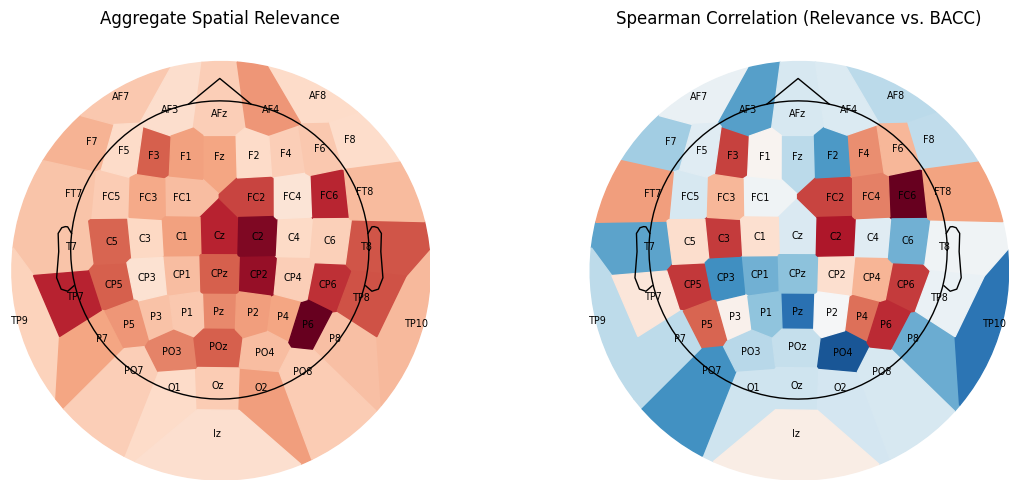

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
mean_spatial = mat_runs_norm.mean(axis=0)
attribution_topomap(
    mean_spatial,
    channel_names=ch_names,
    ax=axes[0]
)
axes[0].set_title("Aggregate Spatial Relevance", fontsize=12)

attribution_topomap(
    corr_df['rho'].values,
    channel_names=ch_names,
    ax=axes[1]
)
axes[1].set_title("Spearman Correlation (Relevance vs. BACC)", fontsize=12)

plt.tight_layout()
STATS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(STATS_DIR / "arousal_topomaps_relevance_and_spearman.png", dpi=300)
print(f"written: {STATS_DIR / 'arousal_topomaps_relevance_and_spearman.png'}")
plt.show()

## 5. Output files: statistics cache

`results/apa_mwu/arousal_stats.json` holds everything needed to check or redo the tests without the run data:
the inputs (channel names, runs, relative relevance matrix, test balanced accuracies), all test results,
the ranksums check, the test settings, the git commit and library versions, and the data folders that were read.
`results/apa_mwu/arousal_electrode_mwu.csv` and `results/apa_mwu/arousal_spearman_bacc.csv` hold the per-electrode
Mann–Whitney U and Spearman results as tables.

In [10]:
MWU_COLUMNS = ['channel_idx', 'channel_name', 'n_x', 'mdn_x', 'q1_x', 'q3_x', 'n_y', 'mdn_y', 'q1_y', 'q3_y', 'U', 'z', 'p', 'p_adj', 'r', 'A', 'n_tied_values', 'sig_raw', 'sig_fdr', 'sentence', 'sentence_short']
stats_cache = {
    "description": "Arousal prediction, frozen_arousal, from_scratch_arousal and finetuned_arousal, 5 runs each",
    "provenance": provenance({label: os.path.realpath(path) for label, path in EXPERIMENT_MAP.items()}),
    "inputs": {
        "channel_names": list(ch_names),
        "runs": run_info,
        "relative_relevance": mat_runs_norm,  # rows: runs (order of "runs"), columns: channel_names
        "test_balanced_accuracy": bacc_vec,
    },
    "electrode_vs_background_mwu": {
        "alternative": "greater (electrode relevance tends to be larger than background relevance)",
        "alpha": alpha,
        "multiple_testing": "Benjamini-Hochberg FDR across electrodes",
        "background_description": background_description,
        "results": sig_df[MWU_COLUMNS],
    },
    "check_against_ranksums": ranksums_check,
    "spearman_relevance_vs_test_balanced_accuracy": {
        "alpha": alpha,
        "multiple_testing": "Benjamini-Hochberg FDR across electrodes",
        "results": corr_df[["channel_idx", "channel_name", "rho", "p_value", "p_adj", "sig_fdr", "apa"]],
    },
}
write_output("arousal_stats.json", stats_cache)
sig_df[MWU_COLUMNS].to_csv(STATS_DIR / "arousal_electrode_mwu.csv", index=False)
print(f"written: {STATS_DIR / 'arousal_electrode_mwu.csv'}")
corr_df.to_csv(STATS_DIR / "arousal_spearman_bacc.csv", index=False)
print(f"written: {STATS_DIR / 'arousal_spearman_bacc.csv'}")

written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/arousal_stats.json
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/arousal_electrode_mwu.csv
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/arousal_spearman_bacc.csv
